##  1. Базовые методы генерации изображений (Pillow, OpenCV, Turtle)

---

### 1. Введение

Современные технологии активно используют **генерацию изображений** — от создания текстур и фонов в играх до генерации реалистичных фотографий нейросетями.
Прежде чем переходить к сложным методам (нейросети, диффузионные модели), необходимо понимать **основы компьютерной графики** и уметь создавать изображения программно с нуля.

На этом занятии мы рассмотрим, как можно сгенерировать изображение средствами Python, без использования готовых картинок.

---

## 2. Основные понятия цифрового изображения

### 🔹 Что такое изображение?

Цифровое изображение — это двумерный массив (матрица), где каждому элементу (пикселю) соответствует цветовое значение.

**Пиксель (pixel)** — минимальный элемент изображения, содержащий информацию о цвете.
Изображение можно представить как таблицу:

```
[[p11, p12, p13, ...],
 [p21, p22, p23, ...],
 ...]
```

Каждый `p` — это набор значений цвета (обычно 3 числа — по каналам RGB).

---

### 🔹 Разрешение и размер изображения

* **Разрешение** — количество пикселей по горизонтали и вертикали (например, 512×512).
* **Соотношение сторон (aspect ratio)** — отношение ширины к высоте.
* **Плотность пикселей (dpi)** влияет на качество при печати, но не при отображении на экране.

---

### 🔹 Цветовые модели

Цветовые модели определяют, как хранится информация о цвете.

|     Модель    | Расшифровка             | Описание                                                            |
| :-----------: | :---------------------- | :------------------------------------------------------------------ |
|    **RGB**    | Red, Green, Blue        | Основная модель для экранов. Каждый цвет — комбинация трёх каналов. |
|    **RGBA**   | Red, Green, Blue, Alpha | То же самое, но с прозрачностью (Alpha).                            |
|    **BGR**    | Blue, Green, Red        | Формат, используемый в OpenCV.                                      |
| **Grayscale** | Оттенки серого          | Один канал (яркость от 0 до 255).                                   |

**Пример:**
Красный цвет в RGB — `(255, 0, 0)`, зелёный — `(0, 255, 0)`, синий — `(0, 0, 255)`.

---

### 🔹 Координатная система изображения

* Начало координат (0, 0) — в **левом верхнем углу**.
* Ось **X** направлена вправо, ось **Y** — вниз.
* Каждая точка (x, y) соответствует одному пикселю.

Пример:

```
(0,0) ───────► X
 │
 ▼
 Y
```

---

### 🔹 Форматы изображений

| Формат         | Особенности                        | Использование             |
| :------------- | :--------------------------------- | :------------------------ |
| **PNG**        | Без потерь, поддержка прозрачности | Логотипы, графика         |
| **JPEG (JPG)** | Сжатие с потерями, меньше размер   | Фото, фоновые изображения |
| **BMP**        | Без сжатия, большой размер         | Редко используется        |
| **TIFF**       | Высокое качество, научная графика  | Печать, анализ данных     |

---

## 3. Обзор библиотек Python для работы с изображениями

### 1. Pillow (PIL)

**Pillow** — это обновлённая версия библиотеки PIL (Python Imaging Library).
Позволяет **создавать**, **обрабатывать**, **фильтровать** и **сохранять** изображения.

**Основные возможности:**

* создание пустых изображений;
* рисование фигур, текста;
* применение фильтров;
* изменение размера, вращение, обрезка.

https://pillow.readthedocs.io/en/stable/reference/ImageDraw.html


In [1]:
# !pip install pillow

In [2]:
from PIL import Image, ImageDraw

# Создание изображения 400x400, белый фон
img = Image.new("RGB", (400, 400), "white")

# Создание объекта для рисования
draw = ImageDraw.Draw(img)

# Рисуем фигуры
draw.rectangle([50, 50, 350, 350], outline="blue", width=3)
draw.ellipse([100, 100, 300, 300], outline="red", width=3)
draw.text((150, 180), "Hello MIIT!", fill="green")

# Просмотр и сохранение
img.show()
img.save("demo.png")

In [3]:
from PIL import Image, ImageDraw

# Создаем холст с белым фоном
img = Image.new("RGB", (400, 400), "white")
draw = ImageDraw.Draw(img)

# Градиент: перебираем каждую строку
for y in range(400):
    r = int(255 * (1 - y / 400))  # Красный уменьшается
    b = int(255 * (y / 400))      # Синий увеличивается
    draw.line([(0, y), (400, y)], fill=(r, 0, b))

# Добавляем прозрачный круг (используем отдельный слой)
circle_layer = Image.new("RGBA", (400, 400), (0, 0, 0, 0))
circle_draw = ImageDraw.Draw(circle_layer)
circle_draw.ellipse((150, 150, 250, 250), fill=(255, 255, 0, 128))  # Желтый с прозрачностью 50%
img = Image.alpha_composite(img.convert("RGBA"), circle_layer).convert("RGB")

# Сохраняем
img.save("pillow_gradient.png")
img.show()

### 2. OpenCV

**OpenCV (Open Source Computer Vision Library)** — мощная библиотека для компьютерного зрения.
Она умеет не только обрабатывать изображения, но и работать с видео, распознаванием объектов и машинным обучением.

**Особенности:**

* Использует массивы NumPy.
* Цветовая модель — **BGR**.
* Позволяет рисовать фигуры, применять фильтры и трансформации.

https://docs.opencv.org/4.x/dc/da5/tutorial_py_drawing_functions.html

In [4]:
import cv2
import numpy as np

# Создание чёрного изображения
img = np.zeros((400, 400, 3), np.uint8)

# Рисуем фигуры
cv2.circle(img, (200, 200), 100, (0, 0, 255), -1)
cv2.rectangle(img, (50, 50), (350, 350), (255, 0, 0), 3)
cv2.putText(img, "Hello, MIIT", (130, 200),
            cv2.FONT_HERSHEY_SIMPLEX, 1, (255, 255, 255), 2)

cv2.imshow("Image", img)
cv2.waitKey(0)
cv2.destroyAllWindows()

qt.qpa.plugin: Could not find the Qt platform plugin "wayland" in "/home/roma/PycharmProjects/university/.venv/lib/python3.14/site-packages/cv2/qt/plugins"

(process:63545): Gtk-WARNING **: 20:25:18.284: Theme parser error: gtk.css:312:16-28: Unknown name of pseudo-class
[63743:63743:1110/202518.385651:ERROR:ui/ozone/platform/wayland/gpu/wayland_surface_factory.cc:249] '--ozone-platform=wayland' is not compatible with Vulkan. Consider switching to '--ozone-platform=x11' or disabling Vulkan
Created TensorFlow Lite XNNPACK delegate for CPU.

(process:63545): Gtk-WARNING **: 20:25:18.524: Use GtkSettings:gtk-interface-color-scheme instead


Окно или вкладка откроются в текущем сеансе браузера.


### 3. Turtle

**Turtle** — библиотека для обучающей графики, основанная на принципе «черепашки», которая оставляет след, перемещаясь по экрану.

**Основные команды:**

* `turtle.forward(x)` — идти вперёд на `x` пикселей;
* `turtle.right(angle)` / `turtle.left(angle)` — повернуть на угол;
* `turtle.circle(r)` — нарисовать окружность;
* `turtle.color("red")`, `turtle.pensize(3)` — настройка пера.

https://docs.python.org/3/library/turtle.html

In [5]:
import turtle

t = turtle.Turtle()
t.speed(10)
for i in range(36):
    t.forward(100)
    t.right(170)
turtle.done()

Terminator: 

In [ ]:
from turtle import speed, bgcolor, colormode, fd, rt, pencolor


speed(20)
bgcolor('black')
r, g, b = 255, 0, 0

for i in range(255*2):
    colormode(255)
    
    if i < 255//3:
        g += 3
    elif i < (255*2)//3:
        r -= 3
    elif i < 255:
        b += 3
    elif i < (255*4)//3:
        g -= 3
    elif i < (255*5)//3:
        r += 3
    else:
        b -= 3
        
    fd(50+i)
    rt(91)
    pencolor(r, g, b)

In [ ]:

import turtle
import math

anms = turtle.Turtle()
anms.color("green")
anms.speed(10000)

anms.shape("turtle")

anms.begin_fill()
'''
for i in range(2000):
    anms.forward(10)
    anms.forward(math.sin(i/10)*25)
    anms.left(20)
'''
for i in range(2000):
    anms.forward(10)
    anms.left(math.sin(i/10)*25)
    anms.left(20)

anms.end_fill()

turtle.mainloop()

### Заданиe c использванием pillow:

Создать изображение 512×512 пикселей с белым фоном.
Нарисовать на нём:
* синий прямоугольник,
* красный круг,
* зелёную линию,
* надпись (своё имя и дата).
Сохранить результат в файл output_pillow.png.*

**Подсказки:**
Использовать Image.new, ImageDraw.Draw, draw.rectangle, draw.ellipse, draw.line, draw.text.
Для выбора цвета можно использовать RGB-значения: (255, 0, 0).


### Задание c использованием turtle:

Использовать библиотеку turtle для рисования простого паттерна (например, звезда, квадрат, спираль).

Для примера можно использовать https://www.turtlegraphics.fun/examples.html

## Задания

### Задание 1. Изображение с помощью Pillow

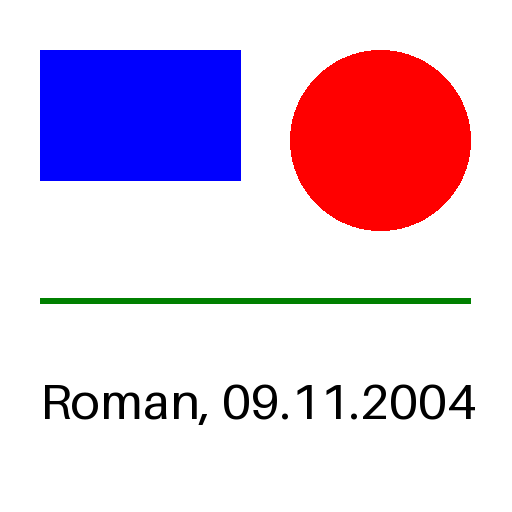

In [7]:
from pathlib import Path

from PIL import Image, ImageDraw, ImageFont
from IPython.display import display

# Создаём изображение: начало координат находится в левом верхнем углу.
image = Image.new("RGB", (512, 512), "white")
draw = ImageDraw.Draw(image)

# Синий прямоугольник и красный круг (его ширина равна высоте).
draw.rectangle((40, 50, 240, 180), fill=(0, 0, 255))
draw.ellipse((290, 50, 470, 230), fill=(255, 0, 0))

# Зелёная линия шириной 6 пикселей.
draw.line((40, 300, 470, 300), fill=(0, 128, 0), width=6)

name = "Roman"
happy = "09.11.2004"
draw.text((40, 370), f"{name}, {happy}", fill="black", font_size=50)

output_path = Path("./output_pillow.png")
image.save(output_path)
display(image)

### Задание 2. Цветная звезда с помощью Turtle

In [12]:
import turtle

screen = turtle.Screen()
screen.setup(width=700, height=700)
screen.title("Звезда")
screen.bgcolor("white")

pen = turtle.Turtle()
pen.speed(0)
pen.width(2)
colors = ["blue", "red", "green", "orange", "purple", "cyan"]

# Начинаем слева, чтобы звезда разместилась в центре окна.
pen.penup()
pen.goto(-150, 50)
pen.pendown()

# Пять одинаковых отрезков и поворот на 144° образуют звезду.
for step in range(5):
    pen.pencolor(colors[step % len(colors)])
    pen.forward(300)
    pen.right(144)

pen.hideturtle()
screen.exitonclick()


Terminator: 